# Fase 7 — Evaluación en distribución sobre TEST (entregable 3)

**Qué pide el enunciado:** IoU, F1, precisión y recall de la clase agua en chips dorados de eventos vistos durante el entrenamiento, más una **matriz de confusión comentada**.

**Protocolo (esto va tal cual a la metodología del informe):**
1. **Selección del modelo solo con validación:** se toma la variante de la ablación (a) con mayor IoU medio en valid (3 semillas). Test no participó en ninguna decisión previa.
2. **Se reportan las 3 semillas** de esa variante en test → media ± desviación (no se elige "la mejor semilla", eso sería optimista).
3. **Umbral:** 0.5 fijado a priori. Como análisis adicional, el umbral que maximiza IoU **en validación** se aplica a test (nunca se ajusta mirando test).
4. Referencia: **Otsu en test** (fase 4): IoU 0.554.

**No necesita GPU** (solo inferencia: ~5–10 min en CPU). Usa los checkpoints de la fase 6 que ya subiste a Drive.

## 0. Preparación

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import sys
from pathlib import Path
RAIZ_PROYECTO = Path('/content/drive/MyDrive/rnap_p2_inundaciones')
sys.path.insert(0, str(RAIZ_PROYECTO))

!pip install -q rasterio

Mounted at /content/drive


## 1. Módulos nuevos de `src/`

In [2]:
%%writefile /content/drive/MyDrive/rnap_p2_inundaciones/src/evaluacion_final.py
"""
evaluacion_final.py
Fase 7 (entregable 3): evaluación EN DISTRIBUCIÓN sobre la partición test (eventos vistos en
entrenamiento, chips nunca vistos). Reglas:
  - El modelo final se elige SOLO con validación (ablación a): mayor IoU medio sobre 3 semillas.
  - Se reportan las 3 semillas de esa variante: media ± desviación en test.
  - Umbral: 0.5 (fijado a priori) y, como análisis adicional, el umbral que maximiza el IoU en
    VALIDACIÓN aplicado después a test (nunca se ajusta nada mirando test).
"""
import numpy as np
import pandas as pd
import torch

from .entrenamiento import cargar_mejor_modelo
from .metricas import metricas_desde_conteos
from .metricas_torch import AcumuladorConfusion

CARPETAS = {"solo_dorados": "combinada", "solo_debiles": "preentreno",
            "mezcla": "mezcla", "preentreno_ajuste": "preentreno_ajuste"}
N_CASILLAS = 200   # resolución del histograma de probabilidades (umbral cada 0.005)


def elegir_variante(ruta_csv_ablacion) -> tuple[str, pd.DataFrame]:
    df = pd.read_csv(ruta_csv_ablacion)
    medias = df.groupby("variante")[["iou", "f1", "precision", "recall"]].agg(["mean", "std"])
    ganadora = medias[("iou", "mean")].idxmax()
    return ganadora, medias.sort_values(("iou", "mean"), ascending=False)


@torch.no_grad()
def evaluar_con_histograma(modelo, cargador, dispositivo):
    """Una sola pasada: acumulador (umbral 0.5) + histogramas de P(agua) para agua y no agua.
    Con los histogramas se puede calcular VP/FP/FN para CUALQUIER umbral sin volver a predecir."""
    modelo.eval()
    acumulador = AcumuladorConfusion(0.5)
    hist_agua = torch.zeros(N_CASILLAS, dtype=torch.float64)
    hist_no_agua = torch.zeros(N_CASILLAS, dtype=torch.float64)
    usar_amp = dispositivo.type == "cuda"
    for imagenes, etiquetas, ids in cargador:
        imagenes, etiquetas = imagenes.to(dispositivo), etiquetas.to(dispositivo)
        with torch.autocast(dispositivo.type, dtype=torch.float16, enabled=usar_amp):
            logits = modelo(imagenes)
        acumulador.actualizar(logits, etiquetas, ids)
        p = torch.sigmoid(logits.float()).squeeze(1)
        for clase, hist in [(1, hist_agua), (0, hist_no_agua)]:
            valores = p[etiquetas == clase]
            hist += torch.histc(valores, bins=N_CASILLAS, min=0, max=1).double().cpu()
    return acumulador, hist_agua.numpy(), hist_no_agua.numpy()


def curva_umbral(hist_agua, hist_no_agua) -> pd.DataFrame:
    """Métricas para cada umbral u: predice agua si P > u (casillas por encima de u)."""
    filas = []
    total_agua, total_no_agua = hist_agua.sum(), hist_no_agua.sum()
    for i in range(1, N_CASILLAS):
        umbral = i / N_CASILLAS
        vp = hist_agua[i:].sum(); fp = hist_no_agua[i:].sum()
        filas.append({"umbral": umbral, **metricas_desde_conteos(vp, fp, total_agua - vp, total_no_agua - fp)})
    return pd.DataFrame(filas)


def evaluar_semillas(carpeta, semillas, cargadores, dir_experimentos, dispositivo) -> dict:
    """Para cada semilla: métricas en test a 0.5, umbral óptimo en valid y métricas en test con ese umbral."""
    resultado = {"filas": [], "acumuladores_test": {}, "curvas_valid": {}, "curvas_test": {}}
    for semilla in semillas:
        modelo, _, _ = cargar_mejor_modelo(dir_experimentos / f"{carpeta}_s{semilla}", dispositivo)
        _, ha_v, hn_v = evaluar_con_histograma(modelo, cargadores["valid"], dispositivo)
        acum_t, ha_t, hn_t = evaluar_con_histograma(modelo, cargadores["test"], dispositivo)
        curva_v, curva_t = curva_umbral(ha_v, hn_v), curva_umbral(ha_t, hn_t)
        umbral_opt = float(curva_v.loc[curva_v["iou"].idxmax(), "umbral"])
        en_test_opt = curva_t.iloc[(curva_t["umbral"] - umbral_opt).abs().idxmin()]
        resultado["filas"].append({"semilla": semilla, "criterio_umbral": "fijo 0.5", "umbral": 0.5, **acum_t.metricas()})
        resultado["filas"].append({"semilla": semilla, "criterio_umbral": "óptimo en valid", "umbral": umbral_opt,
                                   **en_test_opt.drop("umbral").to_dict()})
        resultado["acumuladores_test"][semilla] = acum_t
        resultado["curvas_valid"][semilla], resultado["curvas_test"][semilla] = curva_v, curva_t
        del modelo
    resultado["df"] = pd.DataFrame(resultado["filas"])
    return resultado


def matriz_sumada(acumuladores) -> np.ndarray:
    return sum(a.matriz_confusion() for a in acumuladores.values())


def por_evento_test(acumuladores) -> pd.DataFrame:
    tablas = [a.tabla_por_evento()[["iou", "f1", "omision", "comision"]] for a in acumuladores.values()]
    return pd.concat(tablas).groupby(level=0).mean().sort_values("iou")


Writing /content/drive/MyDrive/rnap_p2_inundaciones/src/evaluacion_final.py


In [3]:
%%writefile /content/drive/MyDrive/rnap_p2_inundaciones/src/visualizacion_final.py
"""
visualizacion_final.py
Mapa de errores por píxel y curva IoU-umbral (fase 7; también se reutiliza en el análisis de fallos).
"""
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# 0 ignorado, 1 VN, 2 VP, 3 FP (agua inventada), 4 FN (agua perdida)
MAPA_ERRORES = ListedColormap(["#ffffff", "#e8e3d6", "#1f5fbf", "#d62728", "#ff9f1c"])
LEYENDA = [Patch(color=c, label=t) for c, t in zip(MAPA_ERRORES.colors[1:], ["VN", "VP", "FP (comisión)", "FN (omisión)"])]


def mapa_errores(etiqueta, probabilidad, umbral=0.5):
    prediccion = probabilidad > umbral
    mapa = np.zeros(etiqueta.shape, dtype=np.int8)
    validos = etiqueta != -1
    mapa[validos & ~prediccion & (etiqueta == 0)] = 1
    mapa[validos & prediccion & (etiqueta == 1)] = 2
    mapa[validos & prediccion & (etiqueta == 0)] = 3
    mapa[validos & ~prediccion & (etiqueta == 1)] = 4
    return mapa


def figura_errores(ejemplos, umbral=0.5, ruta_guardado=None):
    """ejemplos: [(id_chip, vh_normalizado, etiqueta, probabilidad), ...] -> VH | P(agua) | mapa de errores."""
    figura, ejes = plt.subplots(len(ejemplos), 3, figsize=(10, 3.3 * len(ejemplos)))
    ejes = np.atleast_2d(ejes)
    for fila, (id_chip, vh, etiqueta, probabilidad) in enumerate(ejemplos):
        ejes[fila, 0].imshow(vh, cmap="gray", vmin=-2.5, vmax=2.5); ejes[fila, 0].set_title(f"{id_chip} — VH", fontsize=9)
        ejes[fila, 1].imshow(probabilidad, cmap="Blues", vmin=0, vmax=1); ejes[fila, 1].set_title("P(agua)", fontsize=9)
        ejes[fila, 2].imshow(mapa_errores(etiqueta, probabilidad, umbral), cmap=MAPA_ERRORES, vmin=0, vmax=4,
                             interpolation="nearest")
        ejes[fila, 2].set_title("Errores", fontsize=9)
        for eje in ejes[fila]:
            eje.axis("off")
    figura.legend(handles=LEYENDA, loc="lower center", ncol=4, frameon=False)
    figura.tight_layout(rect=(0, 0.03, 1, 1))
    if ruta_guardado:
        figura.savefig(ruta_guardado, dpi=150, bbox_inches="tight")
    return figura


def figura_curva_umbral(curvas_valid, curvas_test, ruta_guardado=None):
    figura, eje = plt.subplots(figsize=(6.5, 4))
    for semilla in curvas_valid:
        eje.plot(curvas_valid[semilla]["umbral"], curvas_valid[semilla]["iou"], color="#7a9cc6", alpha=0.8,
                 label="valid" if semilla == list(curvas_valid)[0] else None)
        eje.plot(curvas_test[semilla]["umbral"], curvas_test[semilla]["iou"], color="#1f5fbf",
                 label="test" if semilla == list(curvas_valid)[0] else None)
    eje.axvline(0.5, ls="--", color="gray", label="umbral 0.5")
    eje.set_xlabel("Umbral sobre P(agua)"); eje.set_ylabel("IoU agua"); eje.set_title("IoU vs. umbral (una línea por semilla)")
    eje.legend(); eje.grid(alpha=0.3)
    figura.tight_layout()
    if ruta_guardado:
        figura.savefig(ruta_guardado, dpi=150, bbox_inches="tight")
    return figura


Writing /content/drive/MyDrive/rnap_p2_inundaciones/src/visualizacion_final.py


## 2. Imports, datos y cargadores

In [4]:
import pandas as pd
import torch

from src.configuracion import *
from src.utilidades import fijar_semilla, obtener_dispositivo
from src.descarga import descargar_mano
from src.preprocesamiento import Normalizador
from src.cargadores import crear_cargadores
from src.evaluacion import predecir_probabilidades
from src.evaluacion_final import (CARPETAS, elegir_variante, evaluar_semillas, matriz_sumada, por_evento_test)
from src.visualizacion_metricas import figura_matriz_confusion
from src.visualizacion_final import figura_errores, figura_curva_umbral

dispositivo = obtener_dispositivo()       # con o sin GPU
fijar_semilla(SEMILLA)
descargar_mano()
normalizador = Normalizador.desde_json(DIR_RESULTADOS / 'f1_estadisticas_normalizacion.json')
cargadores = crear_cargadores(normalizador, tamano_lote=4, tamano_recorte=256, num_workers=2, semilla=SEMILLA)
linea_base_otsu = pd.read_csv(DIR_RESULTADOS / 'f4_linea_base_otsu.csv', index_col=0)
DIR_EXPERIMENTOS = DIR_RESULTADOS / 'experimentos'
SEMILLAS = [42, 7, 123]

OJO: sin GPU. En Colab: Entorno de ejecución > Cambiar tipo > T4 GPU
[descargando] S1Hand ...
[descargando] LabelHand ...
[descargando] S1OtsuLabelHand ...
[descargando] flood_handlabeled ...


Cargando chips en RAM:   0%|          | 0/252 [00:00<?, ?it/s]

train   : 252 chips ->  63 lotes


Cargando chips en RAM:   0%|          | 0/89 [00:00<?, ?it/s]

valid   :  89 chips ->  45 lotes


Cargando chips en RAM:   0%|          | 0/90 [00:00<?, ?it/s]

test    :  90 chips ->  45 lotes


Cargando chips en RAM:   0%|          | 0/15 [00:00<?, ?it/s]

bolivia :  15 chips ->   8 lotes


## 3. Elección del modelo final (solo con validación)
Ranking de la ablación (a) por IoU medio en valid. **Antes de seguir, verifica** que existan en Drive las carpetas `resultados/experimentos/<carpeta>_s42`, `_s7` y `_s123` de la ganadora.

In [5]:
variante_final, ranking = elegir_variante(DIR_RESULTADOS / 'f6a_ablacion_corridas.csv')
carpeta_final = CARPETAS[variante_final]
print(f"Modelo final: {variante_final}  (carpetas {carpeta_final}_s*)")
for s in SEMILLAS:
    ruta = DIR_EXPERIMENTOS / f'{carpeta_final}_s{s}' / 'mejor.pt'
    print(f"  {ruta.relative_to(RAIZ_PROYECTO)}: {'OK' if ruta.exists() else 'FALTA'}")
ranking.round(3)

Modelo final: solo_dorados  (carpetas combinada_s*)
  resultados/experimentos/combinada_s42/mejor.pt: OK
  resultados/experimentos/combinada_s7/mejor.pt: OK
  resultados/experimentos/combinada_s123/mejor.pt: OK


iou            f1        precision        recall       
                    mean    std   mean    std      mean    std   mean    std
variante                                                                    
solo_dorados       0.644  0.002  0.783  0.002     0.822  0.013  0.749  0.008
preentreno_ajuste  0.641  0.005  0.781  0.004     0.823  0.024  0.744  0.015
mezcla             0.571  0.004  0.727  0.003     0.751  0.024  0.706  0.024
solo_debiles       0.562  0.009  0.720  0.008     0.731  0.006  0.709  0.013

## 4. Evaluación en test (3 semillas, umbral 0.5 y umbral óptimo de valid)

In [6]:
resultado = evaluar_semillas(carpeta_final, SEMILLAS, cargadores, DIR_EXPERIMENTOS, dispositivo)
df_test = resultado['df']
df_test.to_csv(DIR_RESULTADOS / 'f7_test_por_semilla.csv', index=False)
display(df_test[['semilla', 'criterio_umbral', 'umbral', 'iou', 'f1', 'precision', 'recall', 'omision', 'comision']].round(4))

metricas = ['iou', 'f1', 'precision', 'recall', 'omision', 'comision']
resumen = df_test.groupby('criterio_umbral')[metricas].agg(['mean', 'std'])
resumen.to_csv(DIR_RESULTADOS / 'f7_test_resumen.csv')
resumen.round(3)

,semilla,criterio_umbral,umbral,iou,f1,precision,recall,omision,comision
0,42,fijo 0.5,0.500,0.6722,0.8040,0.8276,0.7816,0.2184,0.1724
1,42,óptimo en valid,0.310,0.6689,0.8016,0.7990,0.8043,0.1957,0.2010
2,7,fijo 0.5,0.500,0.6669,0.8002,0.8054,0.7950,0.2050,0.1946
3,7,óptimo en valid,0.370,0.6653,0.7990,0.7873,0.8111,0.1889,0.2127
4,123,fijo 0.5,0.500,0.6670,0.8002,0.8113,0.7895,0.2105,0.1887
5,123,óptimo en valid,0.345,0.6640,0.7981,0.7861,0.8105,0.1895,0.2139


iou            f1        precision        recall         \
                  mean    std   mean    std      mean    std   mean    std   
criterio_umbral                                                              
fijo 0.5         0.669  0.003  0.801  0.002     0.815  0.011  0.789  0.007   
óptimo en valid  0.666  0.003  0.800  0.002     0.791  0.007  0.809  0.004   

                omision        comision         
                   mean    std     mean    std  
criterio_umbral                                 
fijo 0.5          0.211  0.007    0.185  0.011  
óptimo en valid   0.191  0.004    0.209  0.007

## 5. Comparación con Otsu en test

In [7]:
medias = df_test.groupby('criterio_umbral')[metricas].mean()
comparacion = pd.concat([linea_base_otsu.loc[['test'], metricas].rename(index={'test': 'Otsu'}),
                         medias.rename(index=lambda c: f'U-Net {variante_final} ({c})')])
comparacion.loc['Mejora absoluta IoU (0.5 vs Otsu)'] = None
comparacion.loc['Mejora absoluta IoU (0.5 vs Otsu)', 'iou'] = medias.loc['fijo 0.5', 'iou'] - linea_base_otsu.loc['test', 'iou']
comparacion.to_csv(DIR_RESULTADOS / 'f7_comparacion_otsu_test.csv')
comparacion.round(3)

,iou,f1,precision,recall,omision,comision
Otsu,0.554,0.713,0.682,0.748,0.252,0.318
U-Net solo_dorados (fijo 0.5),0.669,0.801,0.815,0.789,0.211,0.185
U-Net solo_dorados (óptimo en valid),0.666,0.800,0.791,0.809,0.191,0.209
Mejora absoluta IoU (0.5 vs Otsu),0.114,NaN,NaN,NaN,NaN,NaN


## 6. Matriz de confusión (suma de las 3 semillas, umbral 0.5)
**Para comentar:** en la fila *Real agua*, el % de FN es la **omisión**; en la columna *Pred. agua*, la proporción FP/(FP+VP) es la **comisión**. Compárala con la de Otsu (`figuras/f4_matriz_confusion_otsu_test.png`).

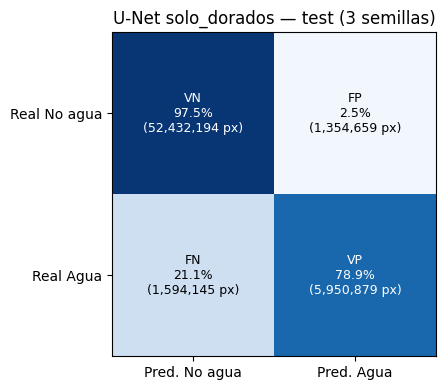

In [8]:
figura_matriz_confusion(matriz_sumada(resultado['acumuladores_test']),
                        f'U-Net {variante_final} — test (3 semillas)', DIR_FIGURAS / 'f7_matriz_confusion_test.png');

## 7. ¿El umbral 0.5 es adecuado? Curva IoU-umbral

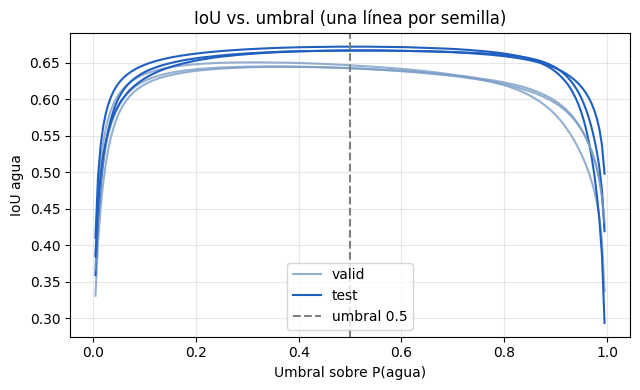

In [9]:
figura_curva_umbral(resultado['curvas_valid'], resultado['curvas_test'], DIR_FIGURAS / 'f7_curva_umbral.png');

## 8. Desglose por evento en test (promedio de semillas)

In [10]:
tabla_eventos = por_evento_test(resultado['acumuladores_test'])
tabla_eventos.to_csv(DIR_RESULTADOS / 'f7_por_evento_test.csv')
tabla_eventos.round(3)

,iou,f1,omision,comision
Pakistan,0.194,0.325,0.709,0.628
Somalia,0.514,0.679,0.429,0.163
Ghana,0.529,0.692,0.430,0.119
USA,0.549,0.709,0.202,0.362
Paraguay,0.599,0.749,0.185,0.307
India,0.721,0.838,0.184,0.138
Spain,0.726,0.841,0.121,0.194
Mekong,0.856,0.923,0.079,0.075
Sri-Lanka,0.877,0.935,0.080,0.051
Nigeria,0.887,0.940,0.040,0.079


## 9. Mapas de error en test (semilla 42)
Azul = VP, rojo = FP (agua inventada), naranja = FN (agua perdida). Un chip por evento, con algo de agua.

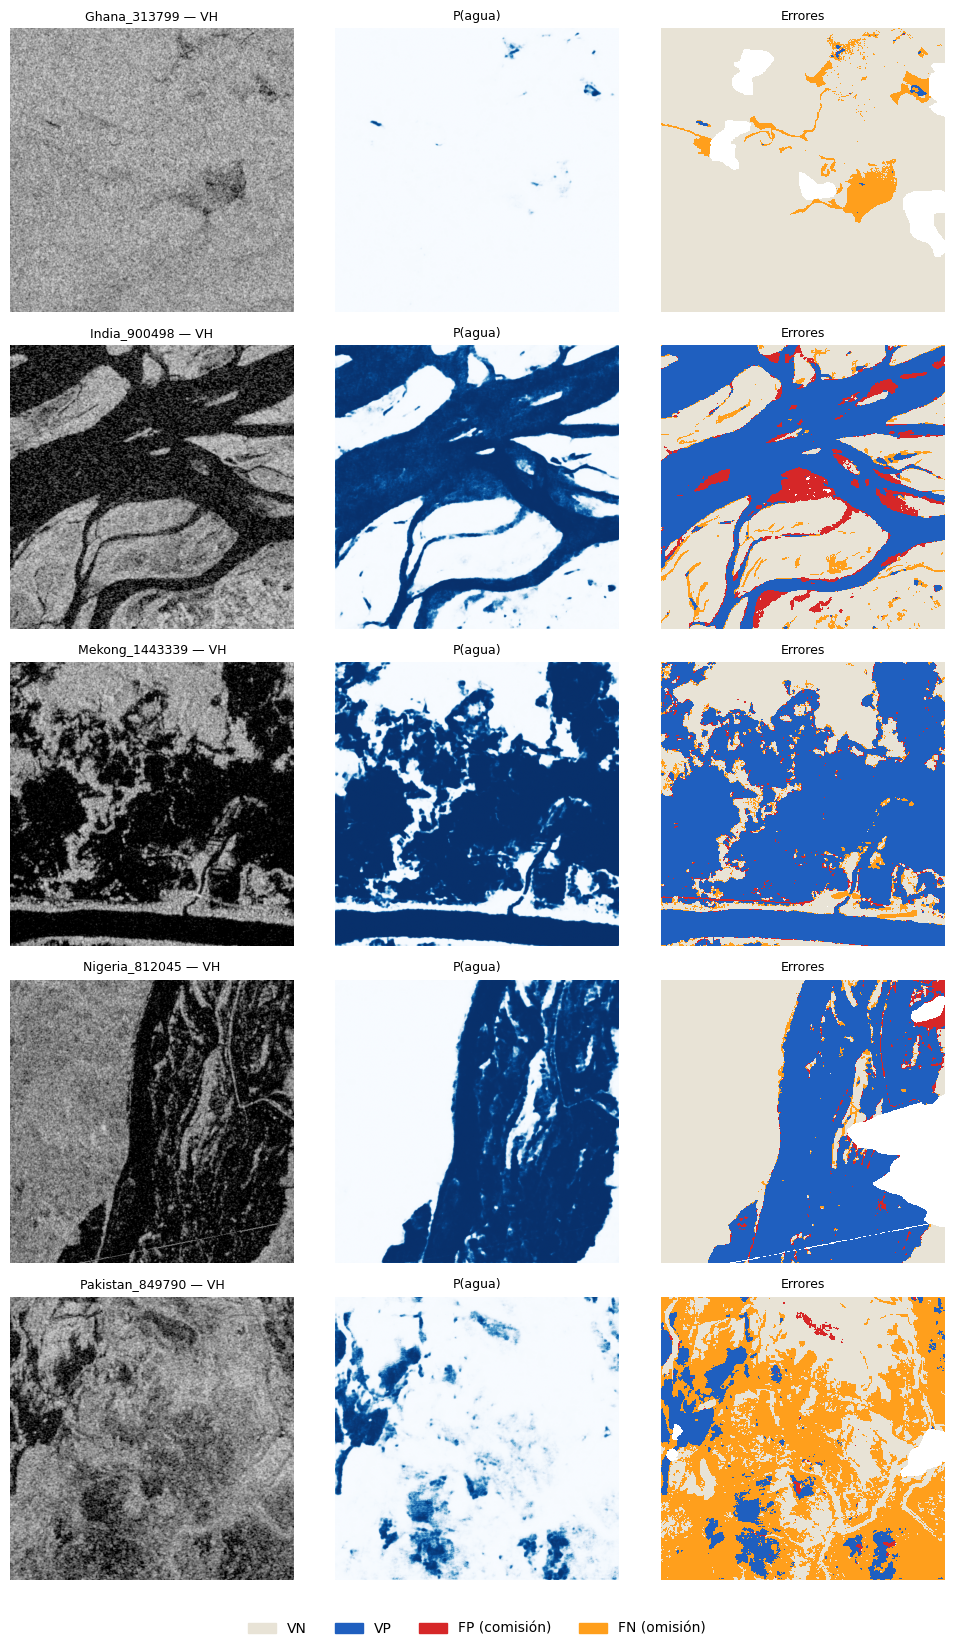

In [11]:
from src.entrenamiento import cargar_mejor_modelo
modelo, _, _ = cargar_mejor_modelo(DIR_EXPERIMENTOS / f'{carpeta_final}_s42', dispositivo)
conjunto_test = cargadores['test'].dataset
eventos_vistos, ejemplos = set(), []
for i, id_chip in enumerate(conjunto_test.ids_chips):
    evento = id_chip.split('_')[0]
    _, etiqueta = conjunto_test.cache[i]
    if evento in eventos_vistos or (etiqueta == 1).mean() < 0.05:
        continue
    eventos_vistos.add(evento)
    imagen, etiqueta, _ = conjunto_test[i]
    ejemplos.append((id_chip, imagen[1].numpy(), etiqueta.numpy(),
                     predecir_probabilidades(modelo, imagen, dispositivo).numpy()))
    if len(ejemplos) == 5:
        break
figura_errores(ejemplos, ruta_guardado=DIR_FIGURAS / 'f7_mapas_error_test.png');

## Para traer a la conversación
Ranking (3), tablas de test (4) y comparación con Otsu (5), la matriz (6), la curva de umbral (7), la tabla por evento (8) y los mapas de error (9).
Con eso redactamos el comentario de la matriz y cerramos el entregable 3.